# Facebook Engagement Analysis — 2026
**Solar Shrestha-Greene** · Deep Creek Lake Concierge & Pine and Paw Lodge Facebook pages

**Goal:** find which posts drive views and interaction, so future posts get more reach and more bookings.

**Data:** Meta Business Suite content export, Jan 1 – Nov 1, 2026 (one row per post).

**Questions**
1. Which post type gets the highest engagement rate?
2. Which day of the week works best?
3. Which time of day works best?
4. Which month / season is strongest?

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Uses the local file if it is next to the notebook, otherwise loads it from GitHub
LOCAL = "facebook_posts_2026.csv"
GITHUB = "https://raw.githubusercontent.com/Solarmoon23/Data-Analyst-Portfolio/main1/facebook-engagement/facebook_posts_2026.csv"
RAW_FILE = LOCAL if os.path.exists(LOCAL) else GITHUB

# Meta exported publish times in Pacific time; +3 converts to Eastern
HOUR_SHIFT = 3

df = pd.read_csv(RAW_FILE)
print(df.shape)
df.head(3)

(225, 33)


,Post ID,Page ID,Page name,Title,Description,Duration (sec),Publish time,Caption type,Permalink,Is crosspost,Is share,Post type,Languages,Custom labels,Funded content status,Data comment,Date,Views,"Reactions, Comments and Shares",Reactions,Comments,Shares,Total clicks,Other Clicks,Link Clicks,Matched Audience Targeting Consumption (Photo Click),Approximate content monetization earnings,Seconds viewed,Average Seconds viewed,Estimated earnings (USD),Ad CPM (USD),Ad impressions,Matched Audience Targeting Consumption (Video Click)
0,1724912412967655,100063467386524,Deep Creek Lake Concierge,Your reel,NaN,20,10/31/2026 06:00,NaN,https://www.facebook.com/reel/1399383088850584/,0,0,Videos,NaN,NaN,NaN,NaN,Lifetime,82,0,0,0,0,0,NaN,NaN,NaN,0.0,949.547,16.956,0.0,NaN,NaN,NaN
1,2154910201763667,100063467386524,Deep Creek Lake Concierge,Your reel,NaN,25,10/30/2026 12:34,NaN,https://www.facebook.com/groups/1050176332237065/permalink/2154910201763667/,1,0,Videos,NaN,NaN,NaN,NaN,Lifetime,8,0,0,0,0,0,NaN,NaN,NaN,0.0,16.751,2.093,NaN,NaN,NaN,NaN
2,1841267606885222,100063467386524,Deep Creek Lake Concierge,Your reel,NaN,25,10/30/2026 12:33,NaN,https://www.facebook.com/groups/526405545038108/permalink/1841267606885222/,1,0,Videos,NaN,NaN,NaN,NaN,Lifetime,19,0,0,0,0,0,NaN,NaN,NaN,0.0,131.962,8.797,NaN,NaN,NaN,NaN


## Step 1 — Clean the data

In [2]:
# Keep only the columns we need, with simple names
keep = {
    "Post ID": "post_id",
    "Page name": "page",
    "Title": "caption",
    "Publish time": "publish_time",
    "Post type": "post_type",
    "Is crosspost": "is_crosspost",
    "Is share": "is_share",
    "Duration (sec)": "video_seconds",
    "Views": "views",
    "Reactions": "reactions",
    "Comments": "comments",
    "Shares": "shares",
    "Reactions, Comments and Shares": "interactions",
    "Total clicks": "clicks",
}
clean = df[list(keep)].rename(columns=keep).copy()

# Short page names
clean["page"] = clean["page"].replace({
    "Deep Creek Lake Concierge": "DCLC",
    "Pine and Paw Lodge - Deep Creek Lake, MD": "Pine & Paw Lodge",
})

# Reels are videos; "Your reel" is a placeholder, not a caption
clean["post_type"] = clean["post_type"].replace({"Reels": "Videos"})
clean.loc[clean["caption"].eq("Your reel"), "caption"] = ""
clean["caption"] = clean["caption"].fillna("")

# Dates and times
clean["publish_time"] = pd.to_datetime(clean["publish_time"], format="%m/%d/%Y %H:%M") + pd.Timedelta(hours=HOUR_SHIFT)
clean["date"] = clean["publish_time"].dt.date
clean["month"] = clean["publish_time"].dt.month
clean["month_name"] = clean["publish_time"].dt.strftime("%b")
clean["day_of_week"] = clean["publish_time"].dt.day_name()
clean["hour"] = clean["publish_time"].dt.hour
clean["time_of_day"] = pd.cut(clean["hour"], bins=[-1, 5, 11, 16, 20, 23],
                              labels=["Night (12–5am)", "Morning (6–11am)", "Afternoon (12–4pm)",
                                      "Evening (5–8pm)", "Late (9–11pm)"])
clean["season"] = clean["month"].map({12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
                                      6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"})

# Caption features
clean["caption_length"] = clean["caption"].str.len()
clean["has_link"] = clean["caption"].str.contains("http", case=False)
clean["has_cta"] = clean["caption"].str.contains(r"book|call|text|visit|reserve|discount|off", case=False)

# Key metrics
clean["engagement_rate"] = clean["interactions"] / clean["views"]   # interactions per view
clean["click_rate"] = clean["clicks"] / clean["views"]

# Quality checks
print("Duplicates:", clean["post_id"].duplicated().sum())
print("Zero-view posts:", (clean["views"] == 0).sum())
clean = clean.drop_duplicates("post_id")
clean = clean[clean["views"] > 0]
print("Rows after cleaning:", len(clean), "(should be 225)")
clean.head()

Duplicates: 0
Zero-view posts: 0
Rows after cleaning: 225 (should be 225)


,post_id,page,caption,publish_time,post_type,is_crosspost,is_share,video_seconds,views,reactions,comments,shares,interactions,clicks,date,month,month_name,day_of_week,hour,time_of_day,season,caption_length,has_link,has_cta,engagement_rate,click_rate
0,1724912412967655,DCLC,,2026-10-31 09:00:00,Videos,0,0,20,82,0,0,0,0,0,2026-10-31,10,Oct,Saturday,9,Morning (6–11am),Fall,0,False,False,0.0,0.0
1,2154910201763667,DCLC,,2026-10-30 15:34:00,Videos,1,0,25,8,0,0,0,0,0,2026-10-30,10,Oct,Friday,15,Afternoon (12–4pm),Fall,0,False,False,0.0,0.0
2,1841267606885222,DCLC,,2026-10-30 15:33:00,Videos,1,0,25,19,0,0,0,0,0,2026-10-30,10,Oct,Friday,15,Afternoon (12–4pm),Fall,0,False,False,0.0,0.0
3,1657062235766463,DCLC,,2026-10-30 15:33:00,Videos,1,0,25,18,0,0,0,0,0,2026-10-30,10,Oct,Friday,15,Afternoon (12–4pm),Fall,0,False,False,0.0,0.0
4,1724885046303725,DCLC,,2026-10-30 15:31:00,Videos,0,0,25,15,2,0,1,3,0,2026-10-30,10,Oct,Friday,15,Afternoon (12–4pm),Fall,0,False,False,0.2,0.0


In [3]:
# Two kinds of rows would distort the comparison:
#  - cross-posts: reels re-posted into Facebook groups (tiny audiences)
#  - shares: posts shared from other pages (their likes/comments count on the ORIGINAL post, so they show ~0)
print(clean.groupby(["is_crosspost", "is_share"]).agg(posts=("post_id", "count"),
      median_views=("views", "median"), median_interactions=("interactions", "median")))
# Keep them in the clean file, but analyze original page posts only.
posts = clean[(clean["is_crosspost"] == 0) & (clean["is_share"] == 0)].copy()
print("Posts analyzed:", len(posts))

clean.drop(columns=["date"]).to_csv("facebook_posts_clean.csv", index=False)

                       posts  median_views  median_interactions
is_crosspost is_share                                          
0            0           169         161.0                 10.0
             1            48          45.0                  0.0
1            0             8          60.0                  0.5
Posts analyzed: 169


## Step 2 — Overview

Views are very skewed (a few posts go viral), so we compare **medians**, not averages.

                  posts  total_views  median_views  median_engagement_rate
page                                                                      
DCLC                123        32864         151.0                   0.040
Pine & Paw Lodge     46        19832         210.5                   0.043
count     169.0
mean      312.0
std       626.0
min        15.0
25%       101.0
50%       161.0
75%       296.0
max      7501.0
Name: views, dtype: float64


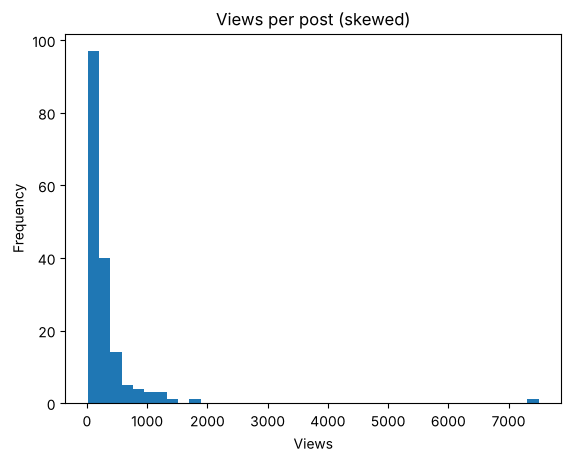

In [4]:
summary = posts.groupby("page").agg(posts=("post_id", "count"), total_views=("views", "sum"),
                                     median_views=("views", "median"),
                                     median_engagement_rate=("engagement_rate", "median")).round(3)
print(summary)
print(posts["views"].describe().round(0))

posts["views"].plot(kind="hist", bins=40, title="Views per post (skewed)")
plt.xlabel("Views"); plt.show()

In [5]:
def compare(col, order=None, min_posts=3):
    g = posts.groupby(col, observed=True).agg(posts=("post_id", "count"),
                                              median_views=("views", "median"),
                                              median_engagement_rate=("engagement_rate", "median"),
                                              median_click_rate=("click_rate", "median"))
    g = g[g["posts"] >= min_posts]
    if order: g = g.reindex([o for o in order if o in g.index])
    return g.round(3)

def bar(table, metric, title, fmt="{:.1%}"):
    ax = table[metric].plot(kind="bar", color="#f08a3c", title=title, rot=0)
    for p, n in zip(ax.patches, table["posts"]):
        ax.annotate(fmt.format(p.get_height()) + f"\n(n={n})", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=8)
    ax.set_ylabel(metric.replace("_", " ")); ax.set_xlabel("")
    ax.margins(y=0.2); plt.tight_layout(); plt.show()

## Q1 — Which post type gets the highest engagement rate?

           posts  median_views  median_engagement_rate  median_click_rate
post_type                                                                
Photos        98         149.5                   0.062              0.051
Videos        54         232.5                   0.036              0.018
Text           7         705.0                   0.015              0.050
Links         10         122.5                   0.010              0.025


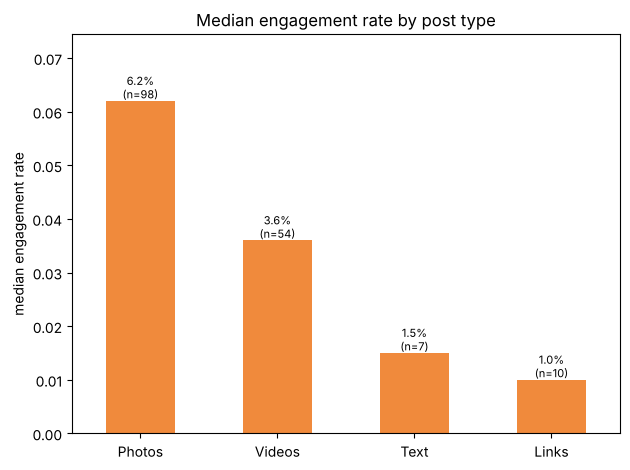

In [6]:
q1 = compare("post_type").sort_values("median_engagement_rate", ascending=False)
print(q1)
bar(q1, "median_engagement_rate", "Median engagement rate by post type")

## Q2 — Which day of the week works best?

             posts  median_views  median_engagement_rate  median_click_rate
day_of_week                                                                
Monday          29         154.0                   0.039              0.036
Tuesday         26         153.5                   0.045              0.020
Wednesday       22         164.0                   0.042              0.042
Thursday        27         219.0                   0.040              0.033
Friday          24         172.0                   0.070              0.041
Saturday        24         156.5                   0.032              0.026
Sunday          17         148.0                   0.032              0.027


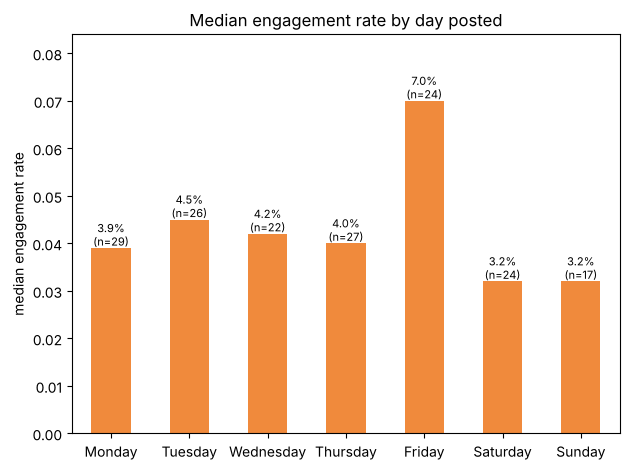

In [7]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
q2 = compare("day_of_week", order=days)
print(q2)
bar(q2, "median_engagement_rate", "Median engagement rate by day posted")

## Q3 — Which time of day works best?

                    posts  ...  median_click_rate
time_of_day                ...                   
Night (12–5am)          7  ...              0.047
Morning (6–11am)      100  ...              0.032
Afternoon (12–4pm)     43  ...              0.030
Evening (5–8pm)        16  ...              0.044
Late (9–11pm)           3  ...              0.005

[5 rows x 4 columns]


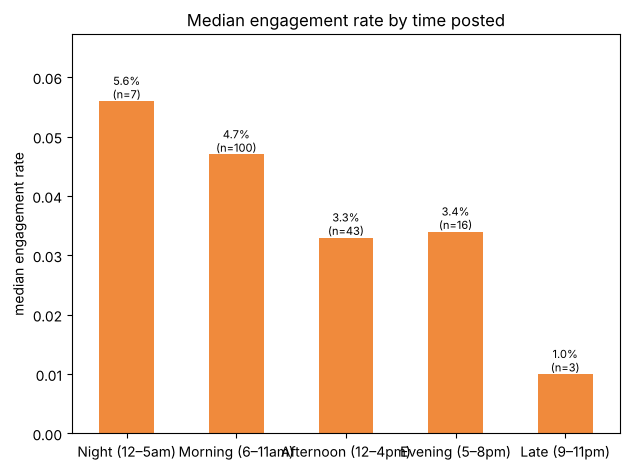

In [8]:
q3 = compare("time_of_day", order=list(posts["time_of_day"].cat.categories))
print(q3)
bar(q3, "median_engagement_rate", "Median engagement rate by time posted")

## Q4 — Which month / season is strongest?

            posts  median_views  median_engagement_rate  median_click_rate
month_name                                                                
Jan             5         287.0                   0.021              0.021
Feb             7         101.0                   0.011              0.020
Mar             9         137.0                   0.013              0.020
Apr            25         160.0                   0.038              0.035
May            29         117.0                   0.069              0.064
Jun            19         201.0                   0.054              0.049
Jul            28         167.0                   0.053              0.017
Aug            24         284.0                   0.045              0.034
Sep            15         219.0                   0.028              0.040
Oct             8         103.5                   0.041              0.007


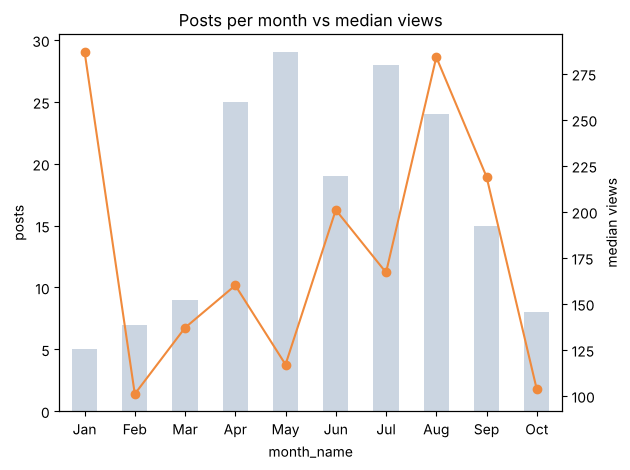

In [9]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
q4 = compare("month_name", order=months, min_posts=1)
print(q4)
fig, ax1 = plt.subplots()
q4["posts"].plot(kind="bar", ax=ax1, color="#cbd5e1", rot=0)
ax1.set_ylabel("posts")
ax2 = ax1.twinx()
ax2.plot(range(len(q4)), q4["median_views"], color="#f08a3c", marker="o")
ax2.set_ylabel("median views")
plt.title("Posts per month vs median views"); plt.tight_layout(); plt.show()

## Bonus — Calls to action and page comparison

In [10]:
print(compare("has_cta"))
print(compare("page"))

         posts  median_views  median_engagement_rate  median_click_rate
has_cta                                                                
False       54         134.0                   0.037              0.041
True       115         183.0                   0.045              0.031
                  posts  ...  median_click_rate
page                     ...                   
DCLC                123  ...              0.034
Pine & Paw Lodge     46  ...              0.030

[2 rows x 4 columns]


In [11]:
top = posts.sort_values("views", ascending=False)[["publish_time", "page", "post_type", "views", "interactions", "engagement_rate", "caption"]].head(10)
top["caption"] = top["caption"].str.slice(0, 80)
top

,publish_time,page,post_type,views,interactions,engagement_rate,caption
200,2026-08-20 10:25:00,Pine & Paw Lodge,Photos,7501,29,0.003866,"🍁 FALL IS CALLING IN GARRETT COUNTY, MARYLAND! 🍂🏔️\n\nSeptember and October are tw"
207,2026-09-07 09:06:00,Pine & Paw Lodge,Photos,1812,18,0.009934,🍁 Your perfect fall escape is waiting at Pine & Paw Lodge! Surrounded by the bre
174,2026-04-28 12:44:00,DCLC,Videos,1428,17,0.011905,👇 Promo Code + Booking Details 👇\n\n🌐 Book now with code: DCLC26 and save $10 off
18,2026-09-17 21:42:00,DCLC,Text,1275,9,0.007059,"🍁🏔️ WHAT’S HAPPENING IN GARRETT COUNTY, MD — SEPTEMBER & OCTOBER 2026! 🍂✨\n\nFall"
141,2026-03-21 15:47:00,DCLC,Links,1205,13,0.010788,🌿✨ Escape to the Wild — Maryland’s First Glamping Experience Awaits! ✨🌿\n\nDreamin
77,2026-06-21 08:30:00,DCLC,Videos,1173,11,0.009378,Watch out for the bear!!
142,2026-03-26 05:25:00,DCLC,Videos,1082,14,0.012939,Glamping in your mind?
130,2026-01-27 13:22:00,DCLC,Photos,1015,4,0.003941,"Snow Removal for Deep Creek Rentals ❄️\n\nMake sure your guests arrive to a clean,"
215,2026-06-24 14:10:00,Pine & Paw Lodge,Text,1013,15,0.014808,☀️ JULY AVAILABILITY ALERT ☀️\n\nSummer is almost fully booked at Pine & Paw Lodge
58,2026-07-16 08:57:00,DCLC,Photos,948,15,0.015823,Better days are waiting for you at the Wild Yough!\nBook your hut at https://dclc


## Step 3 — The same questions in SQL
Loads the clean data into an in-memory SQL database (SQLite, no install needed).
These queries match `facebook_analysis.sql` (written for MySQL).
SQL uses overall rates (total interactions ÷ total views), so numbers differ slightly from the medians above.

In [12]:
import sqlite3
con = sqlite3.connect(":memory:")
clean.drop(columns=["date"]).assign(has_cta=clean["has_cta"].astype(int),
                                    time_of_day=clean["time_of_day"].astype(str)).to_sql("facebook_posts", con, index=False)
con.execute("""CREATE VIEW original_posts AS
               SELECT * FROM facebook_posts WHERE is_crosspost = 0 AND is_share = 0""")

def sql(query):
    return pd.read_sql(query, con)

sql("SELECT COUNT(*) AS original_posts FROM original_posts")   # should be 169

,original_posts
0,169


In [13]:
# Q1. Post type
sql("""
SELECT post_type, COUNT(*) AS posts, ROUND(AVG(views), 0) AS avg_views,
       ROUND(100.0 * SUM(interactions) / SUM(views), 2) AS engagement_rate_pct
FROM original_posts
GROUP BY post_type
ORDER BY engagement_rate_pct DESC
""")

,post_type,posts,avg_views,engagement_rate_pct
0,Photos,98,296.0,4.21
1,Videos,54,302.0,3.18
2,Links,10,295.0,1.46
3,Text,7,634.0,1.40


In [14]:
# Q2. Day of week
sql("""
SELECT day_of_week, COUNT(*) AS posts,
       ROUND(100.0 * SUM(interactions) / SUM(views), 2) AS engagement_rate_pct
FROM original_posts
GROUP BY day_of_week
ORDER BY engagement_rate_pct DESC
""")

,day_of_week,posts,engagement_rate_pct
0,Friday,24,5.76
1,Tuesday,26,4.13
2,Wednesday,22,4.09
3,Saturday,24,3.86
4,Monday,29,3.70
5,Sunday,17,3.09
6,Thursday,27,2.13


In [15]:
# Q3. Time of day
sql("""
SELECT time_of_day, COUNT(*) AS posts,
       ROUND(100.0 * SUM(interactions) / SUM(views), 2) AS engagement_rate_pct
FROM original_posts
GROUP BY time_of_day
HAVING COUNT(*) >= 5
ORDER BY engagement_rate_pct DESC
""")

,time_of_day,posts,engagement_rate_pct
0,Evening (5–8pm),16,4.25
1,Night (12–5am),7,3.96
2,Morning (6–11am),100,3.57
3,Afternoon (12–4pm),43,3.34


In [16]:
# Q4. Month, with a running total of views (window function)
sql("""
SELECT month, month_name, COUNT(*) AS posts, SUM(views) AS views,
       ROUND(100.0 * SUM(interactions) / SUM(views), 2) AS engagement_rate_pct,
       SUM(SUM(views)) OVER (ORDER BY month) AS running_total_views
FROM original_posts
GROUP BY month, month_name
ORDER BY month
""")

,month,month_name,posts,views,engagement_rate_pct,running_total_views
0,1,Jan,5,2002,1.40,2002
1,2,Feb,7,776,1.16,2778
2,3,Mar,9,3636,1.29,6414
3,4,Apr,25,7861,3.35,14275
4,5,May,29,5367,6.93,19642
5,6,Jun,19,6008,4.16,25650
6,7,Jul,28,6014,5.22,31664
7,8,Aug,24,13859,2.46,45523
8,9,Sep,15,5975,2.73,51498
9,10,Oct,8,1198,4.84,52696


In [17]:
# Top 5 posts per page (window function RANK)
sql("""
SELECT * FROM (
  SELECT page, publish_time, post_type, views, interactions, substr(caption, 1, 60) AS caption_start,
         RANK() OVER (PARTITION BY page ORDER BY views DESC) AS rank_in_page
  FROM original_posts
) WHERE rank_in_page <= 5
ORDER BY page, rank_in_page
""")

,page,publish_time,post_type,views,interactions,caption_start,rank_in_page
0,DCLC,2026-04-28 12:44:00,Videos,1428,17,👇 Promo Code + Booking Details 👇\n\n🌐 Book now with code: DCLC,1
1,DCLC,2026-09-17 21:42:00,Text,1275,9,"🍁🏔️ WHAT’S HAPPENING IN GARRETT COUNTY, MD — SEPTEMBER & OCT",2
2,DCLC,2026-03-21 15:47:00,Links,1205,13,🌿✨ Escape to the Wild — Maryland’s First Glamping Experience,3
3,DCLC,2026-06-21 08:30:00,Videos,1173,11,Watch out for the bear!!,4
4,DCLC,2026-03-26 05:25:00,Videos,1082,14,Glamping in your mind?,5
5,Pine & Paw Lodge,2026-08-20 10:25:00,Photos,7501,29,"🍁 FALL IS CALLING IN GARRETT COUNTY, MARYLAND! 🍂🏔️\n\nSeptembe",1
6,Pine & Paw Lodge,2026-09-07 09:06:00,Photos,1812,18,🍁 Your perfect fall escape is waiting at Pine & Paw Lodge! S,2
7,Pine & Paw Lodge,2026-06-24 14:10:00,Text,1013,15,☀️ JULY AVAILABILITY ALERT ☀️\n\nSummer is almost fully booked,3
8,Pine & Paw Lodge,2026-08-24 09:33:00,Photos,645,13,🌲 **We’re Growing — Thanks to You!** 🐾\n\nWe’re so grateful to,4
9,Pine & Paw Lodge,2026-06-26 14:54:00,Photos,462,10,🌲 **Looking for an easy weekend escape from Columbus?**\n\nLes,5


## Findings & recommendations
1. **Post type:** Photos get the highest engagement (6.2% median vs 3.6% for videos), but videos reach more people (233 vs 150 median views). → Use photos to drive interaction and videos to grow reach.
2. **Day:** Friday posts get 7.0% engagement, vs 3.2–4.5% on other days. → Schedule key promotions and booking offers for Friday.
3. **Time:** Morning posts (6–11am ET) get 4.7% engagement vs about 3.3% in the afternoon and evening. → Keep posting around 9am.
4. **Season:** May–August is strongest (May peaks at 6.9%); February–March drop to about 1%. → Plan winter content and early-booking offers ahead of the slow months.

**Bonus:** Sharing other pages' posts gets far less reach (45 vs 161 median views) and almost no interaction. → Post original content instead of reshares.

**Limits:** ~10 months of data; shared and group cross-posts excluded; times depend on the export's time zone (see HOUR_SHIFT); engagement rate uses views (Meta's export has no separate reach column).